In [1]:
import os
import glob
import pandas as pd

# ==========================================
# CONFIGURATION
# ==========================================
DATA_DIR = 'tmy_data'

print("Starting TMY data sanity check...")

# Find all CSV files in the folder
csv_files = glob.glob(os.path.join(DATA_DIR, '*_tmy.csv'))

if len(csv_files) == 0:
    print(f"Error: No CSV files found in the '{DATA_DIR}' folder.")
    exit()

print(f"Found {len(csv_files)} files to analyze.\n")

# Trackers for our summary
valid_files = 0
invalid_files = 0
files_with_nulls = 0

global_min_temp = 100.0
global_max_temp = -100.0
global_max_ghi = 0.0

# ==========================================
# LOOP THROUGH FILES
# ==========================================
for file in csv_files:
    # Read the file
    df = pd.read_csv(file)
    
    # 1. CHECK ROW COUNT (Should be 8760)
    if len(df) == 8760:
        valid_files += 1
    else:
        invalid_files += 1
        print(f"  -> WARNING: {os.path.basename(file)} has {len(df)} rows instead of 8760!")
        
    # 2. CHECK FOR MISSING DATA (Nulls)
    if df.isnull().sum().sum() > 0:
        files_with_nulls += 1
        print(f"  -> WARNING: {os.path.basename(file)} contains missing/blank values!")
        
    # 3. COLLECT EXTREMES (For reality check)
    # Using temp_air and ghi based on the sample you provided
    if 'temp_air' in df.columns and 'ghi' in df.columns:
        file_min_temp = df['temp_air'].min()
        file_max_temp = df['temp_air'].max()
        file_max_ghi = df['ghi'].max()
        
        if file_min_temp < global_min_temp: global_min_temp = file_min_temp
        if file_max_temp > global_max_temp: global_max_temp = file_max_temp
        if file_max_ghi > global_max_ghi: global_max_ghi = file_max_ghi

# ==========================================
# PRINT FINAL SUMMARY
# ==========================================
print("==================================================")
print("             DATA SANITY CHECK SUMMARY            ")
print("==================================================")
print(f"Total Files Checked:       {len(csv_files)}")
print(f"Files with 8760 hours:     {valid_files} (Ideal)")
if invalid_files > 0 or files_with_nulls > 0:
    print(f"Files with wrong length:   {invalid_files} (Requires attention)")
    print(f"Files with missing data:   {files_with_nulls} (Requires attention)")
else:
    print("Data Integrity:            PERFECT (No missing rows or nulls)")

print("\n==================================================")
print("             PHYSICAL REALITY CHECK               ")
print("==================================================")
print(f"Coldest Temperature Found:  {global_min_temp:.1f} °C")
print(f"Hottest Temperature Found:  {global_max_temp:.1f} °C")
print(f"Highest Solar (GHI) Found:  {global_max_ghi:.1f} W/m²")
print("==================================================")

print("\n[Guide to Reality Check]")
print("- Temperatures should generally be between -40 °C and 50 °C depending on locations.")
print("- Max GHI (Sunlight) should peak somewhere between 800 and 1150 W/m².")

Starting TMY data sanity check...
Found 10 files to analyze.

             DATA SANITY CHECK SUMMARY            
Total Files Checked:       10
Files with 8760 hours:     10 (Ideal)
Data Integrity:            PERFECT (No missing rows or nulls)

             PHYSICAL REALITY CHECK               
Coldest Temperature Found:  -33.7 °C
Hottest Temperature Found:  40.4 °C
Highest Solar (GHI) Found:  1089.0 W/m²

[Guide to Reality Check]
- Temperatures should generally be between -40 °C and 50 °C depending on locations.
- Max GHI (Sunlight) should peak somewhere between 800 and 1150 W/m².


Plotting data for Datacenter Site: 14593270


/var/folders/hj/wb6c_bx91hd1rh23yw_npmdr0000gp/T/ipykernel_79560/2186299472.py:26: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('datetime', inplace=True)


Success! Plot saved as: TMY_plot_14593270.png


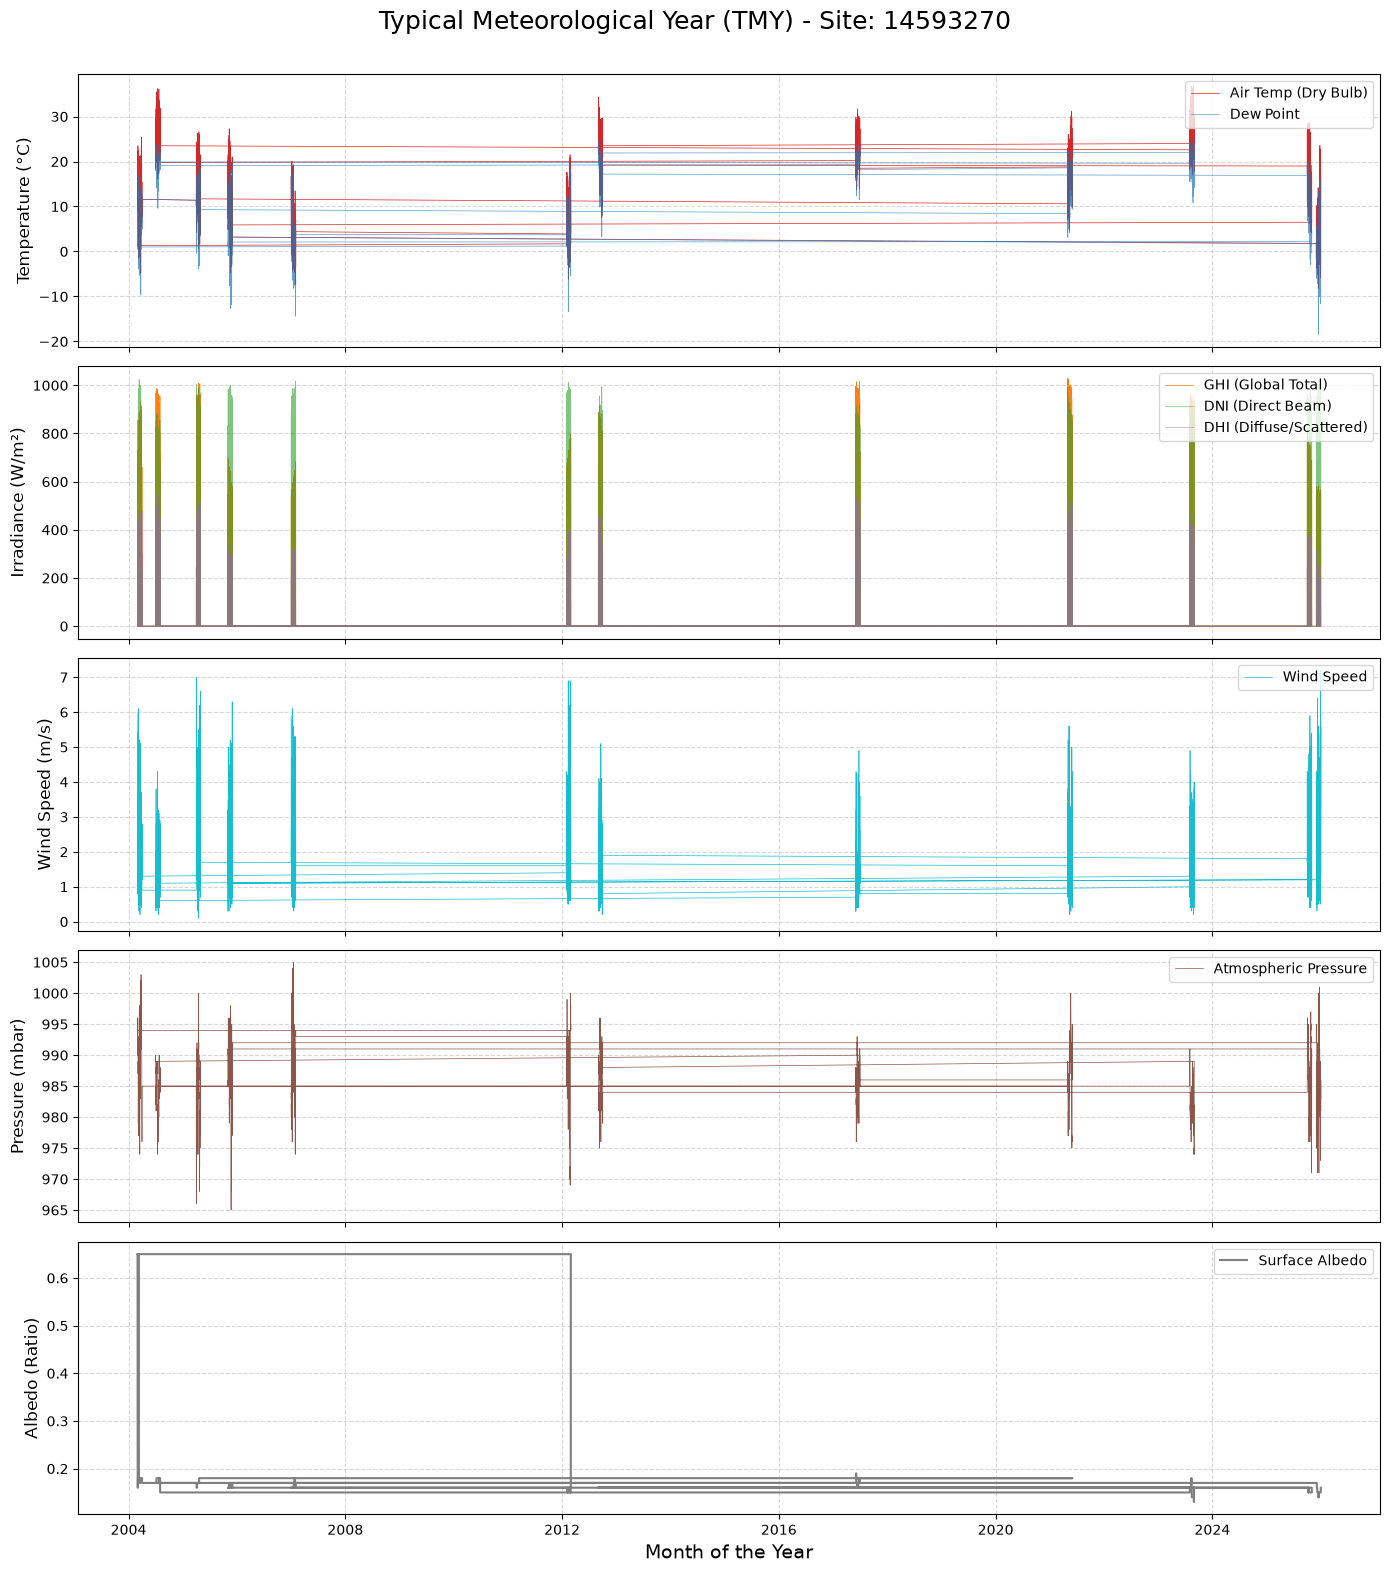

In [3]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. LOAD AN EXAMPLE FILE
# ==========================================
# Find all CSV files and pick the first one
file_list = glob.glob('tmy_data/*_tmy.csv')
if not file_list:
    print("No CSV files found in tmy_data folder!")
    exit()

example_file = file_list[0]
site_id = os.path.basename(example_file).replace('_tmy.csv', '')
print(f"Plotting data for Datacenter Site: {site_id}")

# Read the data
df = pd.read_csv(example_file)

# The first column in your data is the timestamp string. 
# We will convert it to actual datetime objects so the X-axis formats nicely with months
timestamp_col = df.columns[0]
df['datetime'] = pd.to_datetime(df[timestamp_col])
df.set_index('datetime', inplace=True)

# ==========================================
# 2. CREATE THE PLOTS
# ==========================================
# Create a large figure with 5 stacked subplots
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(14, 16), sharex=True)
fig.suptitle(f'Typical Meteorological Year (TMY) - Site: {site_id}', fontsize=18, y=0.98)

# --- Subplot 1: Temperatures ---
# We use a thin line (linewidth=0.5) because 8760 points are dense
axes[0].plot(df.index, df['temp_air'], label='Air Temp (Dry Bulb)', color='tab:red', linewidth=0.5)
axes[0].plot(df.index, df['temp_dew'], label='Dew Point', color='tab:blue', linewidth=0.5, alpha=0.7)
axes[0].set_ylabel('Temperature (°C)', fontsize=12)
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# --- Subplot 2: Solar Irradiance ---
axes[1].plot(df.index, df['ghi'], label='GHI (Global Total)', color='tab:orange', linewidth=0.5)
axes[1].plot(df.index, df['dni'], label='DNI (Direct Beam)', color='tab:green', linewidth=0.5, alpha=0.6)
axes[1].plot(df.index, df['dhi'], label='DHI (Diffuse/Scattered)', color='tab:purple', linewidth=0.5, alpha=0.6)
axes[1].set_ylabel('Irradiance (W/m²)', fontsize=12)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.5)

# --- Subplot 3: Wind Speed ---
axes[2].plot(df.index, df['wind_speed'], label='Wind Speed', color='tab:cyan', linewidth=0.5)
axes[2].set_ylabel('Wind Speed (m/s)', fontsize=12)
axes[2].legend(loc='upper right')
axes[2].grid(True, linestyle='--', alpha=0.5)

# --- Subplot 4: Atmospheric Pressure ---
axes[3].plot(df.index, df['pressure'], label='Atmospheric Pressure', color='tab:brown', linewidth=0.5)
axes[3].set_ylabel('Pressure (mbar)', fontsize=12)
axes[3].legend(loc='upper right')
axes[3].grid(True, linestyle='--', alpha=0.5)

# --- Subplot 5: Surface Albedo ---
axes[4].plot(df.index, df['albedo'], label='Surface Albedo', color='tab:gray', linewidth=1.5)
axes[4].set_ylabel('Albedo (Ratio)', fontsize=12)
axes[4].legend(loc='upper right')
axes[4].grid(True, linestyle='--', alpha=0.5)

# Format the X-axis
axes[4].set_xlabel('Month of the Year', fontsize=14)

# Adjust layout to prevent clipping
plt.tight_layout()
fig.subplots_adjust(top=0.94)

# ==========================================
# 3. SAVE THE PLOT
# ==========================================
output_img = f"TMY_plot_{site_id}.png"
plt.savefig(output_img, dpi=300, bbox_inches='tight')
print(f"Success! Plot saved as: {output_img}")

In [5]:
df['Year'].unique()

array([2007, 2012, 2004, 2005, 2021, 2017, 2023, 2025])

In [10]:
df['Unnamed: 0']

datetime
2007-01-01 00:30:00-05:00    2007-01-01 00:30:00-05:00
2007-01-01 01:30:00-05:00    2007-01-01 01:30:00-05:00
2007-01-01 02:30:00-05:00    2007-01-01 02:30:00-05:00
2007-01-01 03:30:00-05:00    2007-01-01 03:30:00-05:00
2007-01-01 04:30:00-05:00    2007-01-01 04:30:00-05:00
                                       ...            
2025-12-31 19:30:00-05:00    2025-12-31 19:30:00-05:00
2025-12-31 20:30:00-05:00    2025-12-31 20:30:00-05:00
2025-12-31 21:30:00-05:00    2025-12-31 21:30:00-05:00
2025-12-31 22:30:00-05:00    2025-12-31 22:30:00-05:00
2025-12-31 23:30:00-05:00    2025-12-31 23:30:00-05:00
Name: Unnamed: 0, Length: 8760, dtype: str

In [11]:
import pandas as pd
import calendar

# 1. FIND THE DONOR YEAR FOR EACH MONTH
print("=========================================")
print("      TMY DONOR YEARS BY MONTH           ")
print("=========================================")

# Group by Month and grab the first Year for each month
donor_years = df.groupby('Month')['Year'].first()

for month_num, year in donor_years.items():
    # Get the actual name of the month (e.g., 'January')
    month_name = calendar.month_name[month_num]
    print(f"{month_name:<10}: {year}")

# 2. SHOW THE "SEAM" BETWEEN JANUARY AND FEBRUARY
print("\n=========================================")
print("  EXAMPLE OF THE TMY 'SEAM' (Jan -> Feb) ")
print("=========================================")

# January has 31 days * 24 hours = 744 hours. 
# So row indices 742 to 745 will show the exact transition.
# We will just print the Year, Month, Day, and Hour columns:
transition_df = df[['Year', 'Month', 'Day', 'Hour']].iloc[742:746]
print(transition_df.to_string(index=False))

      TMY DONOR YEARS BY MONTH           
January   : 2007
February  : 2012
March     : 2004
April     : 2005
May       : 2021
June      : 2017
July      : 2004
August    : 2023
September : 2012
October   : 2025
November  : 2005
December  : 2025

  EXAMPLE OF THE TMY 'SEAM' (Jan -> Feb) 
 Year  Month  Day  Hour
 2007      1   31    22
 2007      1   31    23
 2012      2    1     0
 2012      2    1     1


Plotting Frankenstein Data for Site: 14593270
Calculating Wet Bulb temperatures...


/var/folders/hj/wb6c_bx91hd1rh23yw_npmdr0000gp/T/ipykernel_79560/3247220793.py:48: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('dummy_date', inplace=True)



Success! Plot saved as: Frankenstein_Plot_Condensed_14593270.png


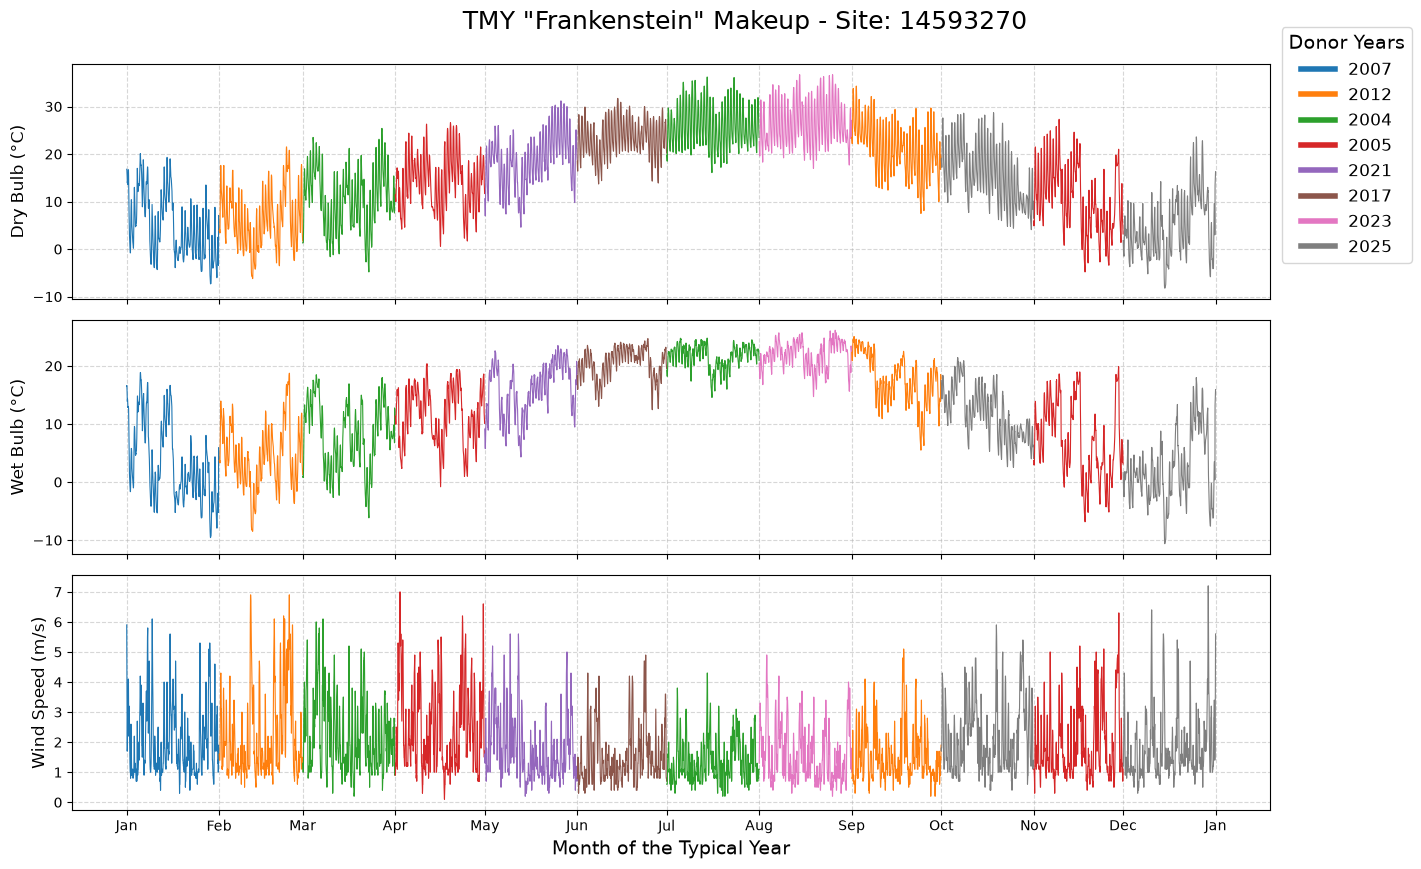

In [14]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.dates as mdates

# ==========================================
# 1. LOAD THE DATA
# ==========================================
file_list = glob.glob('tmy_data/*_tmy.csv')
if not file_list:
    print("No CSV files found in tmy_data folder!")
    exit()

example_file = file_list[0]
site_id = os.path.basename(example_file).replace('_tmy.csv', '')
print(f"Plotting Frankenstein Data for Site: {site_id}")

df = pd.read_csv(example_file)

# ==========================================
# 2. CALCULATE WET BULB TEMPERATURE
# ==========================================
print("Calculating Wet Bulb temperatures...")
# Step A: Calculate Relative Humidity (RH) using the Magnus-Tetens formula
es = 6.112 * np.exp((17.67 * df['temp_air']) / (df['temp_air'] + 243.5)) 
ea = 6.112 * np.exp((17.67 * df['temp_dew']) / (df['temp_dew'] + 243.5)) 
df['rh'] = 100.0 * (ea / es) 

# Step B: Calculate Wet Bulb using Stull's Empirical Equation (T in Celsius, RH in %)
T = df['temp_air']
rh = df['rh']
df['temp_wet'] = (T * np.arctan(0.151977 * (rh + 8.313659)**0.5) +
                  np.arctan(T + rh) -
                  np.arctan(rh - 1.676331) +
                  0.00391838 * (rh)**1.5 * np.arctan(0.023101 * rh) -
                  4.686035)

# ==========================================
# 3. CREATE A "DUMMY" DATETIME FOR THE X-AXIS
# ==========================================
df['dummy_date'] = pd.to_datetime(
    '2022-' + df['Month'].astype(str) + '-' + df['Day'].astype(str) + ' ' + 
    df['Hour'].astype(str) + ':' + df['Minute'].astype(str)
)
df.set_index('dummy_date', inplace=True)

# ==========================================
# 4. SET UP COLORS FOR EACH DONOR YEAR
# ==========================================
unique_years = df['Year'].unique()
cmap = plt.get_cmap('tab10')  
year_colors = {year: cmap(i % 10) for i, year in enumerate(unique_years)}

# ==========================================
# 5. CREATE THE PLOTS
# ==========================================
# Reduced to 3 rows
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(15, 9), sharex=True)
fig.suptitle(f'TMY "Frankenstein" Makeup - Site: {site_id}', fontsize=18, y=0.96)

# Loop through each month and plot chunks color-coded by donor year
for month in range(1, 13):
    m_df = df[df['Month'] == month]
    donor_year = m_df['Year'].iloc[0]
    color = year_colors[donor_year]
    
    # Subplot 1: Air Temperature (Dry Bulb)
    axes[0].plot(m_df.index, m_df['temp_air'], color=color, linewidth=0.8)
    
    # Subplot 2: Wet Bulb Temperature
    axes[1].plot(m_df.index, m_df['temp_wet'], color=color, linewidth=0.8)
    
    # Subplot 3: Wind Speed
    axes[2].plot(m_df.index, m_df['wind_speed'], color=color, linewidth=0.8)

# ==========================================
# 6. FORMATTING & LEGEND
# ==========================================
axes[0].set_ylabel('Dry Bulb (°C)', fontsize=12)
axes[1].set_ylabel('Wet Bulb (°C)', fontsize=12)
axes[2].set_ylabel('Wind Speed (m/s)', fontsize=12)

# Format X-Axis to show Month names (applied to the bottom plot, axes[2])
axes[2].xaxis.set_major_locator(mdates.MonthLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
axes[2].set_xlabel('Month of the Typical Year', fontsize=14)

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.5)

# Create Legend
legend_elements = [Line2D([0], [0], color=year_colors[y], lw=4, label=str(y)) for y in unique_years]
fig.legend(handles=legend_elements, loc='upper right', title="Donor Years", 
           bbox_to_anchor=(0.95, 0.95), fontsize=12, title_fontsize=14)

plt.tight_layout()
fig.subplots_adjust(top=0.90, right=0.85)

# ==========================================
# 7. SAVE
# ==========================================
output_img = f"Frankenstein_Plot_Condensed_{site_id}.png"
plt.savefig(output_img, dpi=300, bbox_inches='tight')
print(f"\nSuccess! Plot saved as: {output_img}")